# Demo — model tersimpan (tanpa training ulang)

Run penelitian lengkap (notebook 11) butuh **10,2 jam** di Kaggle. Untuk demo,
model ANN-LM yang sudah dilatih **disimpan ke file** (notebook 16), jadi di
sini hanya:

1. ambil satu potongan data sensor asli (window N = 700 sampel = 2,4 hari),
2. beri kerusakan buatan ke sensor pilihan,
3. hitung entropi EDM-Fuzzy dan JSD-Fuzzy untuk potongan itu (beberapa detik),
4. model tersimpan langsung menebak: **normal atau rusak, jenis apa, dan sensor mana**.

## Cara pakai (3 langkah)

| Langkah | Di Kaggle | Di laptop (Jupyter/VS Code) |
|---|---|---|
| 1. Buka | buka link kernel → klik **Copy & Edit** | buka file `sidang/03_Demo_Model_Tersimpan.ipynb` |
| 2. Atur (boleh dilewati) | ubah sel **Konfigurasi** (hari, sensor, jenis fault) | sama |
| 3. Jalankan | menu **Run → Run all** | menu **Run → Run All Cells** |

Seluruh notebook selesai kira-kira **1 menit**. Tiap langkah di bawah punya tiga
keterangan: **apa yang terjadi**, **apa yang dilihat**, dan **kalimat untuk
menjelaskan**. Panduan lengkap + naskah demo: `sidang/PANDUAN_DEMO.md`.

> Tidak ada yang perlu dipasang atau dilatih. Kalau ada error, jalankan ulang
> **Run all** sekali; kalau masih error lihat bagian *Kalau ada masalah* di panduan.

### Langkah 1 — Muat model yang sudah dilatih

- **Apa yang terjadi:** notebook membuka 10 file model (5 skenario × 2 metode).
- **Apa yang dilihat:** tabel daftar model + **F1 CV resmi** (angka dari notebook 11).
- **Kalimat untuk menjelaskan:** *"Ini model yang sudah dilatih dan disimpan, jadi
  tidak perlu training 10 jam lagi. Angka F1 di kanan adalah hasil uji resmi
  (cross-validation) di penelitian."*

In [1]:
# === Setup: cari folder model + muat semua model tersimpan ===
import glob, json, os, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib

cands = ["models", "../models"] + [str(Path(p).parent) for p in
         glob.glob("/kaggle/input/**/meta.json", recursive=True)]
MODEL_DIR = next((Path(c) for c in cands if (Path(c) / "meta.json").exists()), None)
if MODEL_DIR is None:
    raise FileNotFoundError("Folder models/ tidak ditemukan. Jalankan simpan_model.py "
                            "atau tambahkan output kernel 'simpan-model-final-deteksi-fault' sebagai input.")
sys.path.insert(0, str(MODEL_DIR.resolve()))      # deteksi_fault_core.py ikut tersimpan di models/
import deteksi_fault_core as core

meta = json.loads((MODEL_DIR / "meta.json").read_text())
MODELS = {}
for row in meta["models"]:
    b = joblib.load(MODEL_DIR / row["file"])
    MODELS[(b["scenario_short"], b["method"])] = b

print(f"Model dari: {MODEL_DIR.resolve()}")
print(f"Dibuat {meta['dibuat']} | commit {meta['commit']} | window N = {meta['window']} "
      f"| {len(MODELS)} model dimuat")
pd.DataFrame([{"Skenario": k[0], "Metode": k[1], "Kelas": ", ".join(b["class_names"]),
               "Hidden": tuple(b["hidden"]), "Aktivasi": b["activation"],
               "F1 CV resmi (nb 11)": b["cv_f1_nb11"]}
              for k, b in MODELS.items()])

Model dari: /Users/kelvin/apps/public-files/models
Dibuat 2026-11-20T02:04:57+00:00 | commit da6f6d3 | window N = 700 | 10 model dimuat


,Skenario,Metode,Kelas,Hidden,Aktivasi,F1 CV resmi (nb 11)
0,S1,EDM-Fuzzy,"fault free, faulty","(32, 16)",tanh,0.5945
1,S1,JSD-Fuzzy,"fault free, faulty","(64, 16)",tanh,0.6712
2,S2,EDM-Fuzzy,"fault free, drift, spike, bias, hardware","(16,)",tanh,0.3283
3,S2,JSD-Fuzzy,"fault free, drift, spike, bias, hardware","(16,)",relu,0.3469
4,S3,EDM-Fuzzy,"fault free, bias+HW, drift+bias, drift+HW, spi...","(32,)",relu,0.1836
5,S3,JSD-Fuzzy,"fault free, bias+HW, drift+bias, drift+HW, spi...","(16,)",tanh,0.1962
6,S4,EDM-Fuzzy,"fault free, drift+bias+HW, drift+spike+bias, s...","(64, 16)",tanh,0.3386
7,S4,JSD-Fuzzy,"fault free, drift+bias+HW, drift+spike+bias, s...","(64, 16)",tanh,0.4257
8,S5,EDM-Fuzzy,"fault free, drift+spike+bias+HW","(32, 16)",relu,0.8037
9,S5,JSD-Fuzzy,"fault free, drift+spike+bias+HW","(64,)",tanh,0.8718


### Langkah 2 — Konfigurasi demo (boleh diubah, boleh dibiarkan)

- `HARI_MULAI`: potongan data mulai hari ke berapa (0–95). Kalau memilih `drift`,
  pakai hari **10** atau **69**: drift hanya muncul di tiga episode 3 hari
  (hari 9,8–12,8 · 39,1–42,1 · 68,5–71,5), sama seperti saat training.
  Hindari hari 1–3, 17–18, 33–49, dan 77–83: di file data asli bagian itu
  berupa garis lurus (nilai tidak berubah pola), jadi grafiknya kurang jelas.
- `SENSOR_RUSAK`: sensor yang diberi kerusakan, mis. `["S2"]` atau `["S1", "S3"]`.
- `FAULT`: jenis kerusakan, satu atau kombinasi dari `drift`, `spike`, `bias`, `hardware`.

Model yang dipakai otomatis: **S1** (normal vs rusak) untuk semua kasus, ditambah
skenario sesuai jumlah fault — 1 fault → **S2**, 2 → **S3**, 3 → **S4**, 4 → **S5**.

**Soal contoh default (hari 10, empat fault di S2):** dipilih karena datanya
hidup dan keempat jenis kerusakan terlihat (termasuk drift), **bukan** karena
tebakannya pasti benar. Satu contoh bisa benar bisa salah — F1 resmi S1 hanya
0,59 (EDM) dan 0,67 (JSD), dan kalau peluang tebakan dekat 50 % artinya model
ragu. Bukti yang adil ada di **Langkah 6** (banyak window acak) dan di angka
CV notebook 11.

Jangan kaget kalau `bias` saja tidak terdeteksi: centroid shifting di dalam
entropi menghapus pergeseran tetap, jadi AUC bias ≈ 0,50 (temuan notebook 12,
`sidang/MAPPING.md`). Model juga tidak sempurna — F1 CV resmi tercantum di
tabel atas; S5 (empat fault sekaligus) paling mudah, S3 paling sulit.

In [2]:
HARI_MULAI = 10
SENSOR_RUSAK = ["S2"]
FAULT = ["drift", "spike", "bias", "hardware"]
SEED = 1

### Langkah 3 — Ambil data asli lalu beri kerusakan buatan

- **Apa yang terjadi:** diambil potongan 700 sampel (5 menit/sampel = 2,4 hari)
  dari data sensor asli. Kerusakan buatan diberikan dengan cara yang **sama
  persis seperti saat training**: ke seluruh deret 98 hari dulu, baru dipotong.
- **Apa yang dilihat:** 4 grafik (S1–S4). **Biru = asli**, **merah = setelah
  diberi kerusakan** (hanya di sensor yang dirusak).
- **Kalimat untuk menjelaskan:** *"Biru adalah data lapangan. Merah adalah data
  yang sama setelah kami beri kerusakan, misalnya lonjakan (spike) atau nilai
  macet/hilang (hardware). Tugas model: tahu mana yang rusak tanpa melihat warnanya."*

Sumber data: file lokal -> ../data_sensor.csv


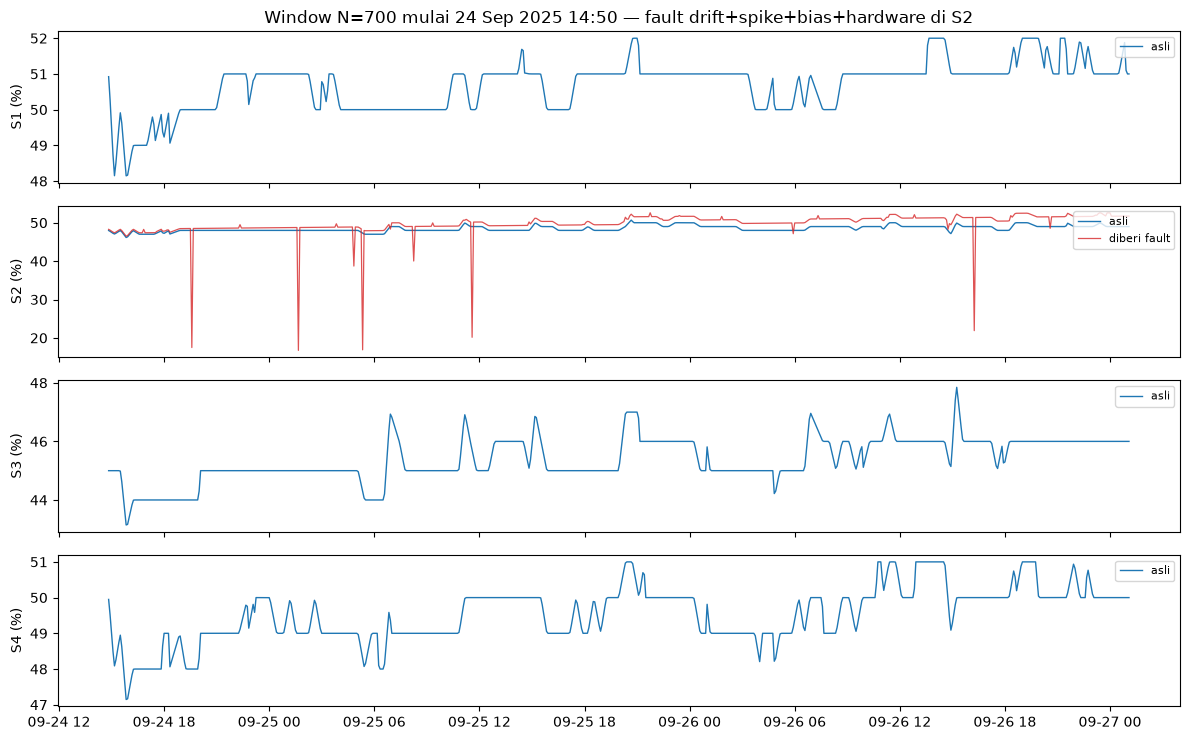

Kondisi: spike+bias+malfunc+drift | porsi sampel yang kena fault per sensor: {'S1': '0.0%', 'S2': '100.0%', 'S3': '0.0%', 'S4': '0.0%'}


In [3]:
# === Potongan data asli vs setelah diberi fault ===
WIN = meta["window"]
df_sync = core.sync_broker(core.load_sensor_data(["data_sensor.csv", "../data_sensor.csv"]))
X = df_sync.to_numpy(dtype=float)
start = int(HARI_MULAI * 86400 / core.SAMPLING_SECONDS)
if start + WIN > len(X):
    raise ValueError(f"HARI_MULAI terlalu besar: maks {(len(X) - WIN) * core.SAMPLING_SECONDS / 86400:.0f}")
sens_idx = [core.SENSORS.index(s) for s in SENSOR_RUSAK]

KONDISI, Y_full, M_full = core.inject_like_training(X, FAULT, sens_idx, seed=SEED)
X_asli = X[start:start + WIN]
X_fault, M_fault = Y_full[start:start + WIN], M_full[start:start + WIN]
waktu = df_sync.index[start:start + WIN]

fig, axs = plt.subplots(4, 1, figsize=(12, 7.5), sharex=True)
for j, ax in enumerate(axs):
    ax.plot(waktu, X_asli[:, j], lw=1, color="tab:blue", label="asli")
    if j in sens_idx:
        ax.plot(waktu, X_fault[:, j], lw=0.9, color="tab:red", alpha=0.8, label="diberi fault")
    ax.set_ylabel(f"{core.SENSORS[j]} (%)")
    ax.legend(loc="upper right", fontsize=8)
axs[0].set_title(f"Window N={WIN} mulai {waktu[0]:%d %b %Y %H:%M} — fault {'+'.join(FAULT)} "
                 f"di {', '.join(SENSOR_RUSAK)}")
plt.tight_layout(); plt.show()
print("Kondisi:", KONDISI, "| porsi sampel yang kena fault per sensor:",
      {core.SENSORS[j]: f"{M_fault[:, j].mean():.1%}" for j in range(4)})
if "drift" in FAULT and not any(a < HARI_MULAI + WIN * core.SAMPLING_SECONDS / 86400 and HARI_MULAI < b
                                for a, b in core.drift_episode_days(len(X))):
    print("Info: potongan ini di luar episode drift, jadi drift tidak terlihat di sini "
          "(komponen lain tetap ada).")
if not (M_fault.mean(axis=0) > core.FAULT_RATIO_THR).any():
    print("PERHATIAN: di potongan ini kerusakannya <= 1% sampel, jadi saat training potongan "
          "seperti ini dianggap normal. Ganti HARI_MULAI (untuk drift: 10 atau 69).")

### Langkah 4 — Ubah sinyal jadi angka "keteraturan pola" (entropi)

- **Apa yang terjadi:** tiap sensor dihitung entropinya pada 15 tingkat
  kekasaran (skala τ = 1..15) → 4 sensor × 15 = 60 angka per potongan.
  Dihitung dua cara: **EDM-Fuzzy** (jarak Euclidean, metode lama) dan
  **JSD-Fuzzy** (Jensen–Shannon, metode usulan).
- **Apa yang dilihat:** garis asli vs garis fault untuk sensor yang dirusak.
  Kalau dua garis berpisah, kerusakannya "terlihat" oleh fitur itu.
- **Kalimat untuk menjelaskan:** *"Entropi mengukur seberapa tidak beraturan pola
  sinyal. Kerusakan mengubah pola, jadi kurvanya bergeser. 60 angka inilah yang
  dibaca jaringan saraf."*

Ekstraksi fitur selesai dalam 2.5 detik (tiap window: 4 sensor x 15 skala = 60 fitur)


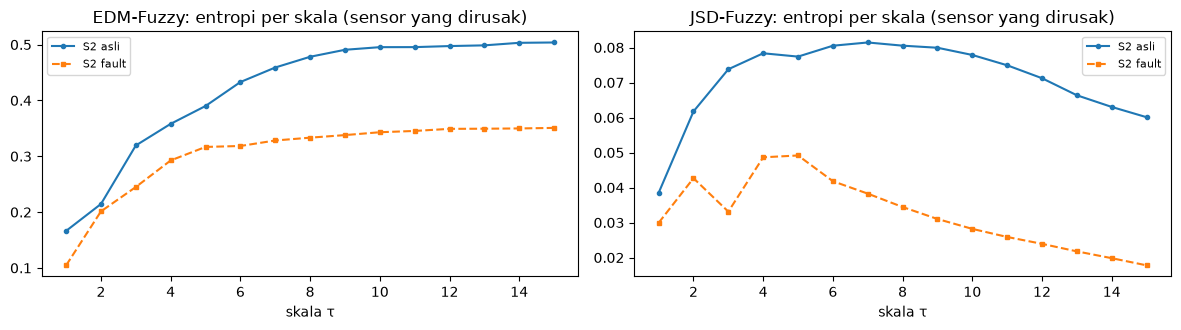

In [4]:
# === Entropi multiskala untuk dua window (asli & fault), dua metode ===
t0 = time.time()
W2 = np.stack([X_asli, X_fault])                 # (2, WIN, 4)
FEAT = {meth: core.concat_multisensor_features(W2, meth, seed=7, n_jobs=-1)
        for meth in ["EDM-Fuzzy", "JSD-Fuzzy"]}
print(f"Ekstraksi fitur selesai dalam {time.time() - t0:.1f} detik "
      f"(tiap window: 4 sensor x {core.T_SCALES} skala = {FEAT['JSD-Fuzzy'].shape[1]} fitur)")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), sharey=False)
for ax, meth in zip(axs, FEAT):
    for j in sens_idx:
        sl = slice(j * core.T_SCALES, (j + 1) * core.T_SCALES)
        ax.plot(core.scales, FEAT[meth][0, sl], "o-", ms=3, label=f"{core.SENSORS[j]} asli")
        ax.plot(core.scales, FEAT[meth][1, sl], "s--", ms=3, label=f"{core.SENSORS[j]} fault")
    ax.set_title(f"{meth}: entropi per skala (sensor yang dirusak)")
    ax.set_xlabel("skala τ"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Langkah 5 — Model menebak

- **Apa yang terjadi:** 60 angka tadi diberikan ke model ANN-LM tersimpan.
- **Apa yang dilihat:**
  - Tabel 1, kolom **Tebakan**: untuk window *asli* jawaban benar `fault free`;
    untuk window *diberi fault* jawaban benar `faulty` (model S1) dan nama
    kerusakannya (model S2–S5). Kolom **Yakin** = peluang tebakan itu.
  - Tabel 2: **sensor mana yang rusak** menurut model vs yang benar. Skor > 0,5
    berarti sensor itu ditebak rusak.
- **Kalimat untuk menjelaskan:** *"Satu contoh bisa benar bisa salah — F1 resmi S1
  0,59–0,67. Peluang dekat 50 % artinya model ragu. Karena itu langkah berikutnya
  menguji banyak potongan acak sekaligus."*

In [5]:
# === Tebakan model tersimpan ===
n_fault = len(set(FAULT))
scen_auto = ["S1", {1: "S2", 2: "S3", 3: "S4", 4: "S5"}[n_fault]]
sc_full = next(k for k in core.LADDER if core.SCEN_SHORT[k] == scen_auto[-1])
kelas_benar = next(nm for nm, conds in core.LADDER[sc_full] if KONDISI in conds)
rows, sens_rows = [], []
for sc in scen_auto:
    for meth in ["EDM-Fuzzy", "JSD-Fuzzy"]:
        b = MODELS.get((sc, meth))
        if b is None:
            continue
        P = b["detektor"].predict_proba(FEAT[meth])
        for wi, nama in enumerate(["asli", "diberi fault"]):
            k = int(P[wi].argmax())
            rows.append({"Window": nama, "Model": sc, "Metode": meth,
                         "Tebakan": b["class_names"][k], "Yakin": f"{P[wi, k]:.0%}",
                         "Semua peluang": ", ".join(f"{c}={p:.0%}" for c, p in zip(b["class_names"], P[wi]))})
        if sc == scen_auto[-1] and b["sensor_id"] is not None:
            skor = b["sensor_id"].decision_function(FEAT[meth][1:2])[0]
            sens_rows.append({"Metode": meth,
                              "Sensor ditebak rusak": ", ".join(s for s, v in zip(core.SENSORS, skor) if v > 0.5) or "-",
                              "Sensor yang benar rusak": ", ".join(SENSOR_RUSAK),
                              **{f"skor {s}": round(float(v), 2) for s, v in zip(core.SENSORS, skor)}})

print(f"Jawaban benar -> window asli: 'fault free' | window diberi fault: 'faulty' (S1) "
      f"dan '{kelas_benar}' ({scen_auto[-1]})")
display(pd.DataFrame(rows))
print("\nSensor mana yang rusak (window fault, ambang skor 0,5):")
display(pd.DataFrame(sens_rows))

Jawaban benar -> window asli: 'fault free' | window diberi fault: 'faulty' (S1) dan 'drift+spike+bias+HW' (S5)


,Window,Model,Metode,Tebakan,Yakin,Semua peluang
0,asli,S1,EDM-Fuzzy,fault free,56%,"fault free=56%, faulty=44%"
1,diberi fault,S1,EDM-Fuzzy,faulty,61%,"fault free=39%, faulty=61%"
2,asli,S1,JSD-Fuzzy,faulty,74%,"fault free=26%, faulty=74%"
3,diberi fault,S1,JSD-Fuzzy,faulty,62%,"fault free=38%, faulty=62%"
4,asli,S5,EDM-Fuzzy,fault free,84%,"fault free=84%, drift+spike+bias+HW=16%"
5,diberi fault,S5,EDM-Fuzzy,fault free,68%,"fault free=68%, drift+spike+bias+HW=32%"
6,asli,S5,JSD-Fuzzy,fault free,60%,"fault free=60%, drift+spike+bias+HW=40%"
7,diberi fault,S5,JSD-Fuzzy,drift+spike+bias+HW,74%,"fault free=26%, drift+spike+bias+HW=74%"



Sensor mana yang rusak (window fault, ambang skor 0,5):


,Metode,Sensor ditebak rusak,Sensor yang benar rusak,skor S1,skor S2,skor S3,skor S4
0,EDM-Fuzzy,S4,S2,-0.15,0.17,0.26,0.88
1,JSD-Fuzzy,"S2, S4",S2,0.28,0.74,0.30,1.04


### Langkah 6 — Uji banyak window sekaligus (supaya tidak cuma satu contoh)

Satu contoh bisa kebetulan benar atau salah. Sel ini mengambil `K` posisi acak,
masing-masing dibuat dua versi (asli, dan diberi kondisi fault acak dari 16
kondisi penelitian di sensor acak — cara injeksi sama dengan training), lalu
menghitung seberapa sering model **S1** (normal vs rusak) benar. Kolom
*Normal benar* dan *Fault benar* memisahkan dua jenis kesalahan.
Rujukan resmi tetap F1 CV notebook 11 (N = 700, S1: EDM 0,59 · JSD 0,67).

In [6]:
K = 15
rng = np.random.default_rng(2026)
Wb, yb, kondisi_b = [], [], []
for i in range(K):
    cond = str(rng.choice(core.ALL_FAULT[1:]))           # 15 kondisi bernama (tanpa "faulty" acak)
    sens = list(rng.choice(4, size=int(rng.integers(1, 5)), replace=False))
    Yf, Mf = core.inject_faults_multisensor(X, core.SCENARIOS[cond], sens, seed=int(rng.integers(1e9)))
    for _ in range(200):                                   # cari potongan yang benar-benar rusak > 1%
        s0 = int(rng.integers(0, len(X) - WIN))
        if (Mf[s0:s0 + WIN].mean(axis=0) > core.FAULT_RATIO_THR).any():
            break
    Wb += [X[s0:s0 + WIN], Yf[s0:s0 + WIN]]; yb += [0, 1]; kondisi_b.append(cond)
Wb, yb = np.stack(Wb), np.array(yb)

t0 = time.time(); hasil = []
for meth in ["EDM-Fuzzy", "JSD-Fuzzy"]:
    Fb = core.concat_multisensor_features(Wb, meth, seed=7, n_jobs=-1)
    pred = MODELS[("S1", meth)]["detektor"].predict(Fb)
    hasil.append({"Metode": meth, "Window diuji": len(yb),
                  "Benar": int((pred == yb).sum()), "Akurasi": f"{(pred == yb).mean():.0%}",
                  "Normal benar": f"{(pred[yb == 0] == 0).mean():.0%}",
                  "Fault benar": f"{(pred[yb == 1] == 1).mean():.0%}",
                  "F1 CV resmi (nb 11, S1)": MODELS[("S1", meth)]["cv_f1_nb11"]})
print(f"{len(yb)} window x 2 metode dalam {time.time() - t0:.1f} detik")
display(pd.DataFrame(hasil))
print("Catatan: posisi window diambil dari data yang juga dipakai melatih model (fault-nya baru), "
      "jadi angka ini ilustrasi demo, bukan pengganti CV.")

30 window x 2 metode dalam 14.7 detik


,Metode,Window diuji,Benar,Akurasi,Normal benar,Fault benar,"F1 CV resmi (nb 11, S1)"
0,EDM-Fuzzy,30,24,80%,80%,80%,0.5945
1,JSD-Fuzzy,30,24,80%,93%,67%,0.6712


Catatan: posisi window diambil dari data yang juga dipakai melatih model (fault-nya baru), jadi angka ini ilustrasi demo, bukan pengganti CV.


### Langkah 7 (opsional) — Latih ulang versi mini (kalau penguji minta lihat proses training)

Fitur entropi semua window sudah tersimpan (`fitur_N700.npz`), jadi yang
dilatih ulang di sini hanya ANN-LM-nya: skenario S1, arsitektur hasil grid,
80 % blok waktu untuk latih dan 20 % untuk uji (blok waktu tidak bercampur).
Grafik menunjukkan *loss* turun di tiap iterasi Levenberg–Marquardt.
Run lengkap (ekstraksi fitur + grid search + CV 5 lipatan x 15 skenario-window)
tetap 10,2 jam di Kaggle, log-nya ada di kernel notebook 11.

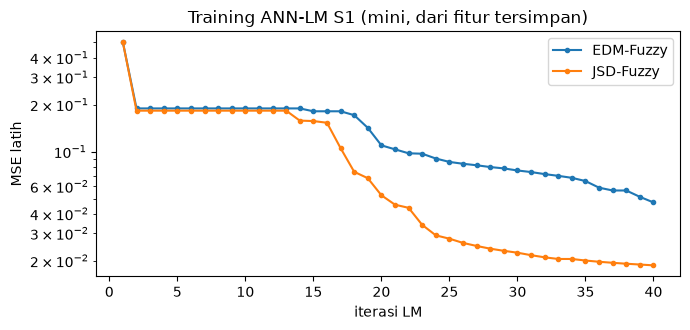

,Metode,Hidden,Aktivasi,Iterasi LM,Status,Detik latih,F1 uji (20% blok waktu)
0,EDM-Fuzzy,"(32, 16)",tanh,40,max_iter,4.5,0.636
1,JSD-Fuzzy,"(64, 16)",tanh,40,max_iter,33.6,0.690


F1 satu split acak bisa naik-turun; angka resmi = rata-rata CV 5 lipatan di notebook 11.


In [7]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import f1_score

Z = np.load(MODEL_DIR / f"fitur_N{WIN}.npz")
keep, yy = core.build_scenario(Z["y_cond"], core.LADDER["S1_Fault_Free_vs_Faulty"])
grp = Z["groups"][keep]
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0).split(keep, yy, grp))

fig, ax = plt.subplots(figsize=(7, 3.4)); out = []
for meth, key in [("EDM-Fuzzy", "F_edm"), ("JSD-Fuzzy", "F_jsd")]:
    F = Z[key][keep]; b = MODELS[("S1", meth)]
    t0 = time.time()
    pipe = core.make_lm_pipeline(b["hidden"], b["activation"], core.LM_ITERS_REFIT, 60.0)
    pipe.fit(F[tr], yy[tr])
    h = pipe.named_steps["lm"].hist_
    ax.plot(range(1, len(h["loss"]) + 1), h["loss"], marker=".", label=meth)
    out.append({"Metode": meth, "Hidden": tuple(b["hidden"]), "Aktivasi": b["activation"],
                "Iterasi LM": h["iters"], "Status": h["status"],
                "Detik latih": round(time.time() - t0, 1),
                "F1 uji (20% blok waktu)": round(f1_score(yy[te], pipe.predict(F[te]), average="macro"), 3)})
ax.set_xlabel("iterasi LM"); ax.set_ylabel("MSE latih"); ax.set_yscale("log")
ax.set_title("Training ANN-LM S1 (mini, dari fitur tersimpan)"); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(out))
print("F1 satu split acak bisa naik-turun; angka resmi = rata-rata CV 5 lipatan di notebook 11.")

---
**Sumber model:** `simpan_model.py` → Kaggle `simpan-model-final-deteksi-fault`
(notebook 16). Kode entropi, simulator fault, dan LM = `deteksi_fault_core.py`,
disalin tanpa perubahan rumus dari notebook 11. Angka performa resmi:
`sidang/MAPPING.md` Tabel B (notebook 11 v3).